<a href="https://colab.research.google.com/github/benly03/DSC-207R/blob/main/Cancer_Risk_Factor_Regression_and_DecisionTree_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Cancer Risk Factor Analysis & Predictive Modeling | Python, scikit-learn, pandas, seaborn, matplotlib (UCSD Graduate Coursework)

- Performed end-to-end clinical data analysis on a 2,000-patient synthetic cancer dataset spanning 21 lifestyle, environmental, and demographic risk variables

- Identified occupational hazards as the strongest predictor of skin cancer using logistic regression (86% test accuracy), with implications for targeted preventative care and at-risk population screening

- Developed a Decision Tree Classifier to predict cancer type from patient history and lifestyle data (~68% accuracy, 5-class), highlighting gaps where richer clinical variables (lab values, biomarkers) could improve diagnostic modeling

- Built a Linear Regression model to predict patient overall risk scores (RMSE: 0.060), demonstrating feasibility of risk stratification from structured EHR-style patient data

In [ ]:
#EXPLAIN AND INGEST YOUR DATASET IN THIS SECTION
#The dataset I chose to use is a cancer dataset.
#I chose this dataset because I was hoping to use a form of regression to do risk factor analysis on different forms of cancer.
#Additionally, this dataset will allow me to implement a DecisionTree to see if I can use ML to predict each patient's cancer type.
#Lastly, cancer research is why I wanted to pursue data science and Biomedical research in the beginning.

#relevant imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


df = pd.read_csv('https://raw.githubusercontent.com/benly03/DSC-207R/refs/heads/main/cancer-risk-factors.csv')

#Data Exploration

In this section I performed a preliminary exploration of the synthetic cancer risk factor dataset containing 2000 patients, covering demographic, lifestyle, environmental and clinical variables. This was done using ```.descibe()``` and ```.head()``` to identify variable ranges, distribution, and outliers.

To further explore the data I created three key visualizations:
- Age distribution histogram, revealing a patient population concentrated between age 55-75

- Cancer type frequency bar chart, showing Lung cancer as the most represented diagnosis

- BMI box plot stratified by cancer type, explore potential body composition patterns across diagnoses.

From this preliminary exploration, I identified several variables that can be removed in data cleaning for better analysis. Those variables being: ```Patient_ID```, removed in accordance with patient privacy and HIPAA compliance best practices, and ```Overall_Risk_Score``` and ```Risk_Level```, removed to prevent data leakage in future modeling.






In [ ]:
#PERFORM AND EXPLAIN YOUR EXPLORATORY ANALYSIS IN THIS SECTION
df.head(10)

,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,Medium
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,Medium
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,1,8,10,0,0,6,0.605082,28.6,2,Medium
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,6,4,8,0,0,8,0.318449,32.1,7,Low
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,9,10,9,0,0,5,0.524358,25.1,2,Medium
5,LU0005,Lung,77,1,10,8,3,0,6,0,...,2,10,7,0,0,0,0.498668,25.1,1,Medium
6,LU0006,Lung,59,0,10,10,0,0,9,4,...,1,10,9,0,0,5,0.662354,32.3,2,High
7,LU0007,Prostate,74,1,8,6,2,1,3,3,...,8,8,7,0,0,1,0.479367,29.1,9,Medium
8,LU0008,Colon,71,1,9,0,3,0,10,4,...,10,8,3,0,0,5,0.497620,24.1,5,Medium
9,LU0009,Skin,55,1,7,1,2,0,0,4,...,5,9,9,0,0,5,0.404837,28.2,1,Medium


In [ ]:
df.columns

Index(['Patient_ID', 'Cancer_Type', 'Age', 'Gender', 'Smoking', 'Alcohol_Use',
       'Obesity', 'Family_History', 'Diet_Red_Meat', 'Diet_Salted_Processed',
       'Fruit_Veg_Intake', 'Physical_Activity', 'Air_Pollution',
       'Occupational_Hazards', 'BRCA_Mutation', 'H_Pylori_Infection',
       'Calcium_Intake', 'Overall_Risk_Score', 'BMI',
       'Physical_Activity_Level', 'Risk_Level'],
      dtype='object')

In [ ]:
df.shape

(2000, 21)

After analyzing the various columns, I will have to remove some variables to make it more manageable. However, I will have to be cautious to not remove variables that are useful in machine learning.

For instance, *"Patient_ID"* would not be necessary in this project so I would be able to remove that variable. Additionally, I am interested in risk factor analysis and so I would be able to remove the *"Overall_Risk_score"* and *"Risk_level"* variables.

In [ ]:
df.drop(columns=['Patient_ID', 'Cancer_Type', 'Gender', 'Risk_Level', 'H_Pylori_Infection', 'BRCA_Mutation', 'Family_History']).describe()

,Age,Smoking,Alcohol_Use,Obesity,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,Air_Pollution,Occupational_Hazards,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,63.248000,5.157000,5.035000,5.967500,5.189500,4.563500,4.927500,4.015000,5.323000,4.979000,3.94050,0.454449,26.183350,4.938500
std,10.462946,3.325339,3.260996,3.061393,3.154452,3.088323,3.045305,2.978458,3.207462,3.212899,3.04887,0.123074,3.947459,3.166027
min,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.029285,15.000000,0.000000
25%,56.000000,2.000000,2.000000,4.000000,3.000000,2.000000,3.000000,1.000000,3.000000,2.000000,1.00000,0.366982,23.500000,2.000000
50%,64.000000,5.000000,5.000000,6.000000,5.000000,4.000000,5.000000,4.000000,5.000000,5.000000,4.00000,0.455399,26.200000,5.000000
75%,70.000000,8.000000,8.000000,9.000000,8.000000,7.000000,8.000000,6.000000,8.000000,8.000000,6.00000,0.539782,28.700000,8.000000
max,90.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.00000,0.852158,41.400000,10.000000


/tmp/ipykernel_4713/2846679070.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cancer_df, ax=axes[1], palette='Set2')


Text(0.5, 0.98, 'Cancer Risk Factor Dataset Distribution Analysis')

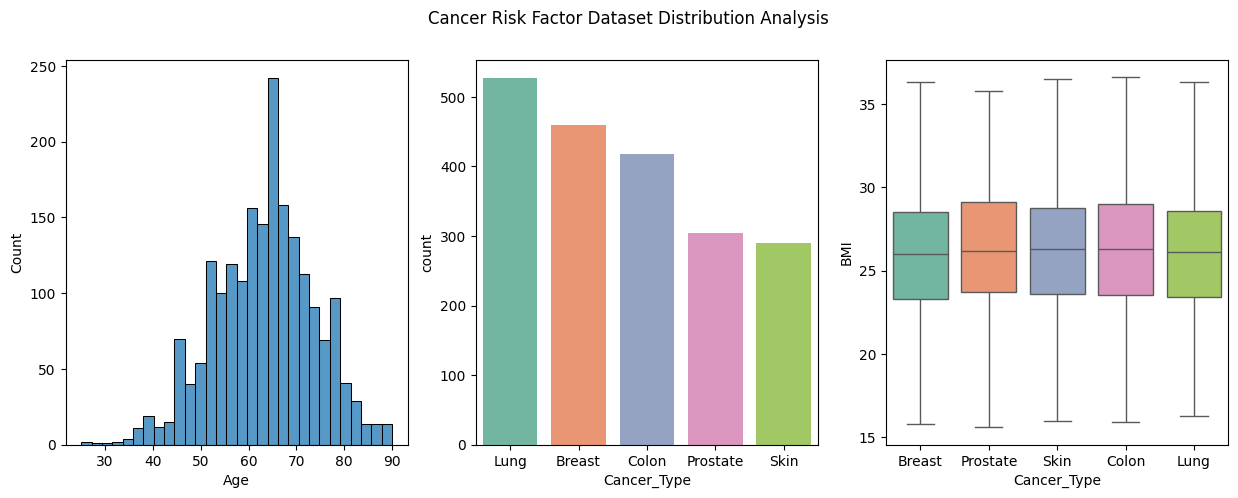

In [ ]:
fig, axes = plt.subplots(1,3, figsize=(15, 5))

sns.histplot(data=df['Age'], ax=axes[0], bins=30)

cancer_df = df['Cancer_Type'].value_counts(ascending=False)
sns.barplot(data=cancer_df, ax=axes[1], palette='Set2')

sns.boxplot(data=df, x='Cancer_Type', y='BMI', ax=axes[2], showfliers=False, palette='Set2', hue='Cancer_Type', legend=False)

plt.suptitle('Cancer Risk Factor Dataset Distribution Analysis')

After viewing the distribution of age, due to the numerous amounts of samples I would consider replacing age with age groups for future analysis. (i.e. 20-29, 30-39, 40-49, etc.)

With the amount of samples, I can also consider limiting my analysis to certain range of age groups. (age >= 30)

#Research Analysis Questions

1. What are the prominent risk factors that are strongly associated with skin cancer?

2. With the given data about a patient's history and lifestyle, can the DecisionTree accurately determine/classify a patient's type of cancer?

3. With the given data about a patient's history, lifestyle and diagnosis, can the LinearRegression library accurately predict a patient's risk score?

#1. What are the prominent risk factors that are strongly associated with skin cancer?

In [ ]:
#isolate patients with skin cancer and clean data of irrelevant data points
skin_cancerdf = df[df['Cancer_Type'] == 'Skin'].copy()

#remove risk score and risk level because we are not determining risk at the moment.
#focus is on correlation of individual risk factors to patients developing skin cancer.
skin_cancerdf.drop(columns=['Patient_ID', 'Cancer_Type', 'Overall_Risk_Score', 'Risk_Level'], inplace=True)
skin_cancerdf.reset_index(drop=True, inplace=True)

skin_cancerdf.head(10)

,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,BMI,Physical_Activity_Level
0,55,1,7,10,7,0,3,3,4,1,8,10,0,0,6,28.6,2
1,55,1,7,1,2,0,0,4,2,5,9,9,0,0,5,28.2,1
2,55,0,9,9,8,0,4,6,3,2,2,10,0,0,4,27.0,6
3,64,1,9,6,3,1,5,4,2,2,9,7,0,0,8,26.4,7
4,57,0,9,3,10,0,3,0,10,0,7,8,0,0,6,21.1,4
5,58,1,8,4,8,0,2,5,1,2,8,10,0,1,5,24.5,3
6,49,0,6,9,9,0,3,2,10,5,10,9,0,0,1,21.6,7
7,57,0,9,8,7,0,4,4,6,7,6,6,0,0,3,30.0,7
8,70,0,4,9,2,0,4,0,8,6,10,4,0,0,2,27.4,8
9,80,0,9,7,6,0,3,3,1,0,4,4,0,0,3,32.3,0


In [ ]:
skin_cancerdf.shape

(290, 17)

In [ ]:
skin_cancerdf.describe()

,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,BMI,Physical_Activity_Level
count,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000
mean,62.193103,0.544828,3.755172,4.931034,5.310345,0.168966,4.155172,4.300000,5.110345,4.100000,5.924138,7.934483,0.010345,0.227586,4.437931,26.249655,5.075862
std,9.157822,0.498847,2.763840,3.192021,2.968152,0.375369,2.836988,3.226673,3.202761,3.113816,2.808989,2.161118,0.101357,0.419999,2.764945,3.911143,3.386484
min,32.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,4.000000,0.000000,0.000000,0.000000,15.000000,0.000000
25%,56.000000,0.000000,2.000000,2.000000,3.000000,0.000000,2.000000,1.250000,3.000000,2.000000,3.000000,6.000000,0.000000,0.000000,2.000000,23.600000,2.000000
50%,62.000000,1.000000,3.000000,5.000000,5.000000,0.000000,4.000000,4.000000,5.000000,3.000000,5.000000,9.000000,0.000000,0.000000,4.000000,26.300000,5.000000
75%,69.000000,1.000000,6.000000,8.000000,8.000000,0.000000,6.000000,7.000000,8.000000,6.000000,9.000000,10.000000,0.000000,0.000000,6.000000,28.775000,8.000000
max,86.000000,1.000000,10.000000,10.000000,10.000000,1.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,1.000000,1.000000,10.000000,36.500000,10.000000


/tmp/ipykernel_4713/1974333619.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Female', 'Male'])


Text(0.5, 0.98, 'Skin Cancer Patient Data Visualization')

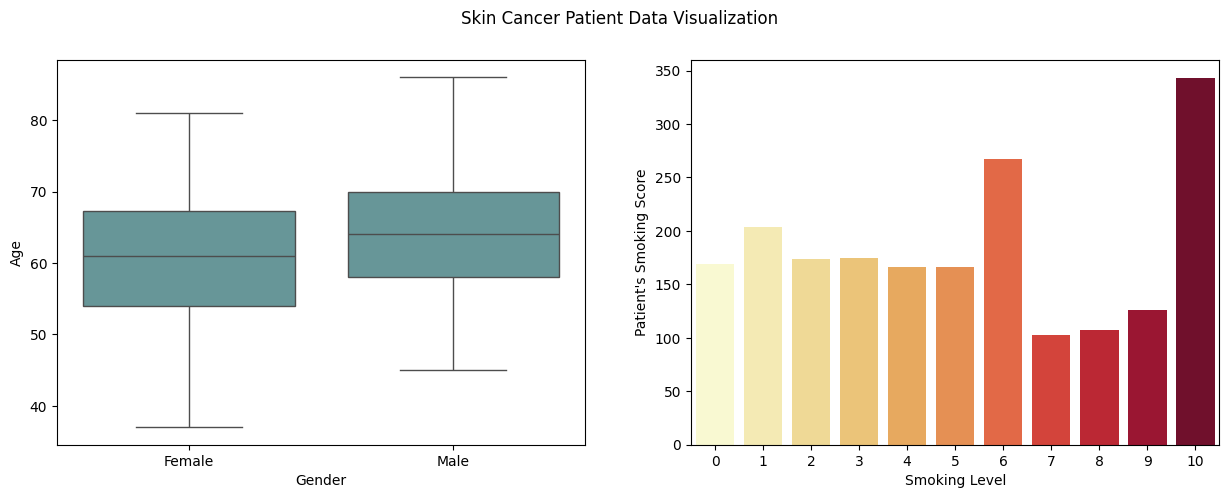

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(15, 5))

sns.boxplot(data=skin_cancerdf, x='Gender', y='Age', color='cadetblue', showfliers=False, ax=axes[0])
axes[0].set_xticklabels(['Female', 'Male'])

sns.countplot(data=df, x='Smoking', hue='Smoking', palette='YlOrRd', legend=False, ax=axes[1])
plt.xlabel('Smoking Level')
plt.ylabel("Patient's Smoking Score")

plt.suptitle('Skin Cancer Patient Data Visualization')

In [ ]:
#add a column to identify patients with skin cancer (1 = skin cancer, 0 = non-skin cancer)
df['Target_skin'] = (df['Cancer_Type'] == 'Skin').astype(int)
df

,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level,Target_skin
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,6,3,1,0,0,0.398696,28.0,5,Medium,0
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,3,3,0,0,5,0.424299,25.4,9,Medium,0
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,8,10,0,0,6,0.605082,28.6,2,Medium,1
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,4,8,0,0,8,0.318449,32.1,7,Low,0
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,10,9,0,0,5,0.524358,25.1,2,Medium,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,ST0395,Colon,60,1,4,6,4,0,10,6,...,5,3,1,0,4,0.437539,30.3,3,Medium,0
1996,ST0396,Prostate,84,1,5,7,8,0,10,0,...,1,3,0,0,2,0.451128,25.9,4,Medium,0
1997,ST0397,Lung,65,0,7,2,10,0,4,2,...,6,0,0,1,0,0.295760,22.5,3,Low,0
1998,ST0398,Lung,64,1,10,2,10,0,2,10,...,4,2,0,0,10,0.422201,25.3,3,Medium,0


Text(0, 0.5, 'Occupational Hazard Score')

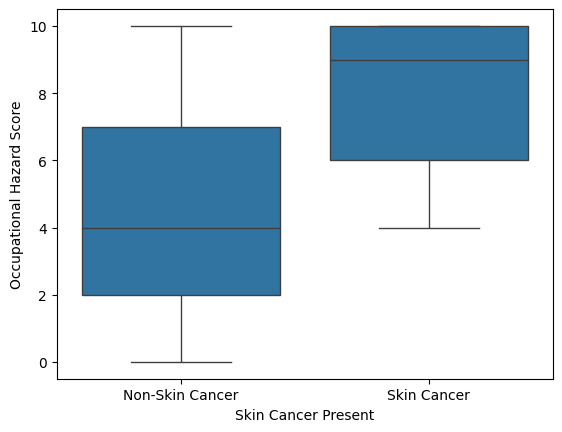

In [ ]:
sns.boxplot(data=df, x='Target_skin', y='Occupational_Hazards')
plt.xticks([0, 1], ['Non-Skin Cancer', 'Skin Cancer'])

plt.xlabel('Skin Cancer Present')
plt.ylabel('Occupational Hazard Score')

In [ ]:
risk_factors = ['Age', 'Gender', 'Smoking', 'Alcohol_Use',
                'Family_History', 'Diet_Red_Meat', 'Air_Pollution',
                'Physical_Activity', 'Occupational_Hazards', 'BMI']

X = df[risk_factors]
y = df['Target_skin']


<Axes: >

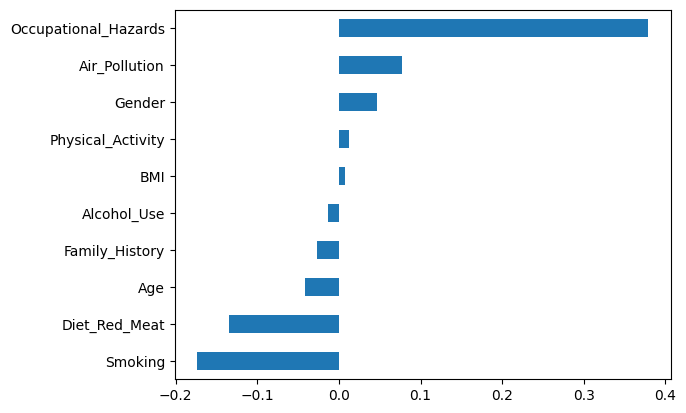

In [ ]:
skin_corr = df[risk_factors].corrwith(df['Target_skin'])
skin_corr.sort_values().plot(kind='barh')

<Axes: >

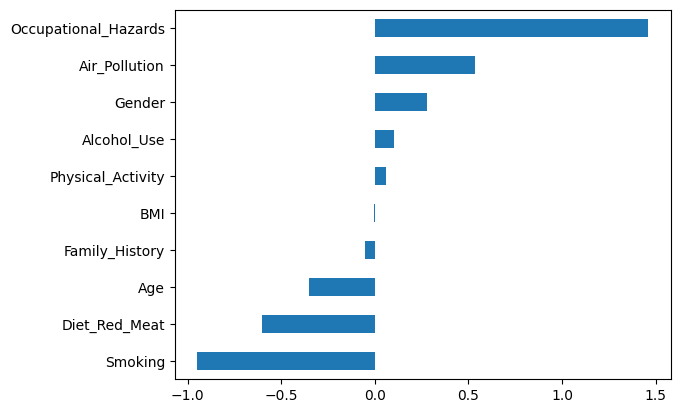

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#split data into test and train data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=100)

model = LogisticRegression(max_iter=50)
model.fit(X_train, y_train)

#visualize regression coefficients
importance = pd.Series(model.coef_[0], index=risk_factors).sort_values()
importance.plot(kind='barh')

In [ ]:
#perform predictions for model accuracy test
pred1 = model.predict(X_train)
pred2 = model.predict(X_test)

In [ ]:
#train accuracy
train_accuracy2 = accuracy_score(y_train, pred1)
train_accuracy2

0.88

In [ ]:
#test accuracy
train_accuracy2 = accuracy_score(y_test, pred2)
train_accuracy2

0.86

#2. With the given data about a patient's history and lifestyle, can the DecisionTree accurately determine/classify a patient's type of cancer?

In [ ]:
#clean dataset to contain only patient history and lifestyle, set target classifier to Cancer_Type
X1_data=df.drop(columns = ['Patient_ID', 'Cancer_Type', 'Overall_Risk_Score', 'Risk_Level', 'Target_skin', 'Physical_Activity_Level'])
y1_target=df['Cancer_Type']

#separate data into train and test sets
X1_train, X1_test, y1_train, y1_test = train_test_split(X1_data, y1_target, test_size=0.2, random_state=100)

In [ ]:
X1_data.head(10)

,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,BMI
0,68,0,7,2,8,0,5,3,7,4,6,3,1,0,0,28.0
1,74,1,8,9,8,0,0,3,7,1,3,3,0,0,5,25.4
2,55,1,7,10,7,0,3,3,4,1,8,10,0,0,6,28.6
3,61,0,6,2,2,0,6,2,4,6,4,8,0,0,8,32.1
4,67,1,10,7,4,0,6,3,10,9,10,9,0,0,5,25.1
5,77,1,10,8,3,0,6,0,6,2,10,7,0,0,0,25.1
6,59,0,10,10,0,0,9,4,0,1,10,9,0,0,5,32.3
7,74,1,8,6,2,1,3,3,2,8,8,7,0,0,1,29.1
8,71,1,9,0,3,0,10,4,6,10,8,3,0,0,5,24.1
9,55,1,7,1,2,0,0,4,2,5,9,9,0,0,5,28.2


In [ ]:
y1_target.head(10)

,Cancer_Type
0,Breast
1,Prostate
2,Skin
3,Colon
4,Lung
5,Lung
6,Lung
7,Prostate
8,Colon
9,Skin


In [ ]:
#initialize Decision Tree and fit data to tree
cancer_classifier = DecisionTreeClassifier(max_leaf_nodes=len(X.columns))
cancer_classifier.fit(X1_train, y1_train)

DecisionTreeClassifier(max_leaf_nodes=10)

In [ ]:
#run predictions
cancer_pred1 = cancer_classifier.predict(X1_train)
cancer_pred2 = cancer_classifier.predict(X1_test)

In [ ]:
#test accuracy of training data
cancer_acc1 = accuracy_score(y1_train, cancer_pred1)
cancer_acc1

0.683125

In [ ]:
#test accuracy of test data
cancer_acc2 = accuracy_score(y1_test, cancer_pred2)
cancer_acc2

0.675

#3. With the given data about a patient's history, lifestyle and diagnosis, can the LogisticRegression library accurately predict a patient's risk score?

In [ ]:
label = LabelEncoder()
risk_score_df = df.copy()

label.fit(risk_score_df.Cancer_Type.drop_duplicates())

risk_score_df.Cancer_Type = label.transform(risk_score_df.Cancer_Type)

In [ ]:
#remove patient_ID as it is not relevant, and other risk score/level indicators
#model should only be given data about the patient
X2_data = risk_score_df.drop(columns = ['Patient_ID', 'Overall_Risk_Score', 'Risk_Level', 'Obesity', 'Target_skin', 'Physical_Activity_Level'])
y2_target = risk_score_df['Overall_Risk_Score']
X2_train, X2_test, y2_train, y2_test = train_test_split(X2_data, y2_target, test_size=0.2, random_state=100)

In [ ]:
X2_data.head(10)

,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Family_History,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,BMI
0,0,68,0,7,2,0,5,3,7,4,6,3,1,0,0,28.0
1,3,74,1,8,9,0,0,3,7,1,3,3,0,0,5,25.4
2,4,55,1,7,10,0,3,3,4,1,8,10,0,0,6,28.6
3,1,61,0,6,2,0,6,2,4,6,4,8,0,0,8,32.1
4,2,67,1,10,7,0,6,3,10,9,10,9,0,0,5,25.1
5,2,77,1,10,8,0,6,0,6,2,10,7,0,0,0,25.1
6,2,59,0,10,10,0,9,4,0,1,10,9,0,0,5,32.3
7,3,74,1,8,6,1,3,3,2,8,8,7,0,0,1,29.1
8,1,71,1,9,0,0,10,4,6,10,8,3,0,0,5,24.1
9,4,55,1,7,1,0,0,4,2,5,9,9,0,0,5,28.2


In [ ]:
risk_score_pred = LinearRegression()
risk_score_pred.fit(X2_train, y2_train)

LinearRegression()

In [ ]:
model_intercept = risk_score_pred.intercept_
print(model_intercept)

0.07812645472562252


In [ ]:
#model training data results
y_train_test = risk_score_pred.predict(X2_train)
rmse_train = np.sqrt(mean_squared_error(y2_train, y_train_test))

print(f"RMSE: {rmse_train}")
print(df['Overall_Risk_Score'].describe())

RMSE: 0.06097298475473481
count    2000.000000
mean        0.454449
std         0.123074
min         0.029285
25%         0.366982
50%         0.455399
75%         0.539782
max         0.852158
Name: Overall_Risk_Score, dtype: float64


In [ ]:
y_pred_test = risk_score_pred.predict(X2_test) #model predicted risk score
print(y_pred_test)

[0.31936504 0.2785416  0.35990101 0.45200386 0.36154984 0.68374474
 0.27247879 0.49055031 0.40630146 0.4055467  0.41716045 0.40995338
 0.53710917 0.38694219 0.56172119 0.56101875 0.55995142 0.37810725
 0.3436518  0.35157445 0.37765444 0.55308835 0.52804242 0.27579677
 0.29859752 0.60265357 0.52264444 0.21560898 0.33032545 0.41615067
 0.45248682 0.33151709 0.37191158 0.3006108  0.4465039  0.51924981
 0.39295775 0.48220692 0.52913383 0.60392661 0.30803305 0.30049587
 0.33080049 0.47922541 0.3814671  0.60888524 0.38417468 0.6629835
 0.57515529 0.62702764 0.29320815 0.59600452 0.2906929  0.67745717
 0.66095473 0.27699326 0.44193039 0.39924744 0.67024803 0.5270871
 0.37468067 0.45766279 0.21462402 0.53922994 0.50390724 0.55430505
 0.38756289 0.44675934 0.43089065 0.44267305 0.52313104 0.45657461
 0.42459489 0.45859742 0.44125795 0.59939085 0.35600473 0.66766546
 0.61137739 0.57567785 0.50823603 0.42073281 0.2748942  0.25047124
 0.38796784 0.45347137 0.51285333 0.45083582 0.414641   0.521779

In [ ]:
rmse_test = np.sqrt(mean_squared_error(y2_test, y_pred_test))

print(f'RMSE: {rmse_test}')

RMSE: 0.05985695795183483


Text(0.5, 0, 'Actual Test Values')

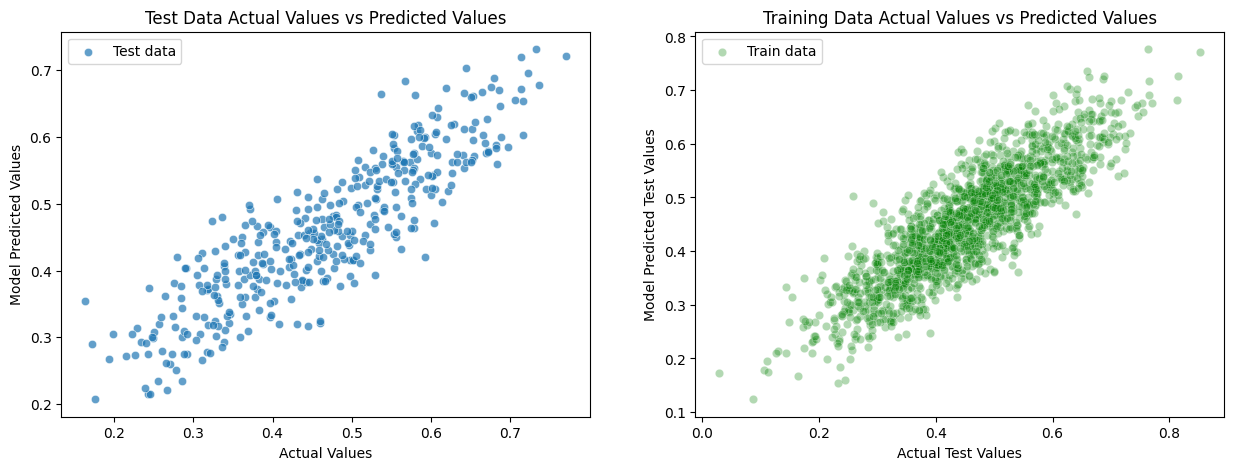

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(15, 5))

#y2_test is the actual values in test dataset, y_pred_tes is the model predicted risk score
sns.scatterplot(x=y2_test, y=y_pred_test, alpha = 0.7, ax=axes[0], label='Test data')
axes[0].set_title('Test Data Actual Values vs Predicted Values')
axes[0].set_ylabel('Model Predicted Values')
axes[0].set_xlabel('Actual Values')


sns.scatterplot(x=y2_train, y=y_train_test, alpha = 0.3, label = 'Train data', ax=axes[1], color='green')
axes[1].set_title('Training Data Actual Values vs Predicted Values')
axes[1].set_ylabel('Model Predicted Test Values')
axes[1].set_xlabel('Actual Test Values')

#Results Interpretation and Analysis

#**Question 1 Results Report**
The first research question I wanted to look into using this synthetic cancer patient dataset was to see what the main factors/variables were that caused a patient to develop skin cancer. The idea was to replicate a risk factor analysis for skin cancer to the best of my abilities in Python.

After cleaning the dataset into a new dataset, skin_cancerdf, I performed a correlation calculation for all variables given in the dataset. It resulted in "Occupational_hazards" being the largest indicator of if the patient will develop skin cancer or not. However, the correlation calculation also yielded unexpected results that may hint towards overlapping variables or not enough data. It showed that patients who smoked had a negative correlation with skin cancer. It is unlikely that smoking is actually a deterant for skin cancer and so it hints to an issue with overlapping variables or missing data.

Moving forward with the logistic regression process, I split the training dataset into 20% test data and 80% training data. After visualizing the model coefficients it yielded similar results to our correlation calculations. Occupational_hazards was still the leading indicator of a patient developing skin cancer. This may be interesting for further research because we are not directly told what is classified as an occupational hazard or how it is scored in the dataset. By looking more in depth into what occupational hazards lead to skin cancer, preventative measures can be taken by informing people who work with those hazards.

#**Question 2 Results Report**

The second research questions I wanted to look into was using the DecisionTreeClassifier to try and accurately predict a patient's cancer diagnosis given the data available in the dataset. The idea was to try and see if the given patient data was sufficient to predict cancer diagnosis or if the model would need more data.

After cleaning the dataset to isolate patient data and history I again split the training dataset into 20% test data and 80% training data. I initialized the DecisionTreeClassifier with max_leaf_nodes = number of features. This was to prevent overfitting the data to the model.

Fitting the model and using it to predict on the training and test data yielded very low accuracy, 68.3% for training data and 67.5% for test data. This could be due to model needing to be fine tuned or possibly the dataset missing crucial factors that could be indicative of a cancer diagnosis. It may be interesting to retry this with a more detailed dataset with patient's lab data such as blood pressure, glucose levels, cholesterol, etc. Also, could retry this with another cancer classifier to classify whether the cancer is malignant or benign.

#**Question 3 Results Report**

The third research question I wanted to look into was using the Linear Regression model to try and accurately predict a patient's "Overall_risk_score". The idea with this research question was to try and see how well the LinearRegression model can predict a patient's risk score or if it is missing crucial data.

In the process of cleaning the data, I removed Patient_ID, Overall_Risk_Score, Risk_Level, Obesity, Target_skin, and Physical_Activity_level. These variables are not relevant to patient data/history and to anonymize patients I removed Patient_ID. After cleaning the dataset, it was split into 20% test data and 80% training data. Following this I initilized the LinearRegression model and fitted the data to the model. After fitting the data I obtained the intercept and RMSE values to understand what the model returned and its accuracy.

The intercept value was 0.078 meaning our baseline risk score for the patients is 0.078. Our RMSE value was 0.060 from the test dataset meaning our model was very accurate in predicting patient "Overall_risk_score". Lastly, I graphed both training data and test data on their own scatterplots to visualize model prediction accuracy. From the scatterplots we can see how accurate the model is by observing the linear and upward trend of the points.


#Video
In this section is a link to a video I made for the final where I explain each part of the notebook and my thought process.

https://drive.google.com/file/d/1vv17KMfUyefXkzNydZIc7aHpjoEJHOVr/view?usp=sharing
